In [1]:
from __future__ import annotations

from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parents[1]
sys.path.append(str(ROOT / "DatabaseScripts"))

from DataFilter import MetroDataQuery

PARQUET_PATH = ROOT / "metro_passengers.parquet"
STATION_ID = 8603328  # Copenhagen Airport
SYSTEM = "m1m2"

# Load Airport station Data

In [2]:
query = (
    MetroDataQuery(PARQUET_PATH)
    .filter_station_id(STATION_ID)
    .filter_system(SYSTEM)
)

df_raw = query.to_pandas(sort_by_time=True)

df_raw.head()

,timestamp,stationId,system,station,ins,outs,passengerNo
0,2024-04-01 00:00:00+00:00,8603328,m1m2,Københavns Lufthavn,33.000000000,5.000000000,19.000000000
1,2024-04-01 00:01:00+00:00,8603328,m1m2,Københavns Lufthavn,29.000000000,2.000000000,15.500000000
2,2024-04-01 00:02:00+00:00,8603328,m1m2,Københavns Lufthavn,35.000000000,5.000000000,20.000000000
3,2024-04-01 00:03:00+00:00,8603328,m1m2,Københavns Lufthavn,22.000000000,4.000000000,13.000000000
4,2024-04-01 00:04:00+00:00,8603328,m1m2,Københavns Lufthavn,20.000000000,13.000000000,16.500000000


In [3]:
df_raw.shape, df_raw.columns

((1051200, 7),
 Index(['timestamp', 'stationId', 'system', 'station', 'ins', 'outs',
        'passengerNo'],
       dtype='str'))

In [4]:
# Basic cleaning 
df = df_raw.copy()

df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)

for col in ["ins", "outs"]:
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)
    df[col] = df[col].clip(lower=0)

df = df.sort_values("timestamp")

df[["timestamp", "ins", "outs"]].head()

,timestamp,ins,outs
0,2024-04-01 00:00:00+00:00,33.0,5.0
1,2024-04-01 00:01:00+00:00,29.0,2.0
2,2024-04-01 00:02:00+00:00,35.0,5.0
3,2024-04-01 00:03:00+00:00,22.0,4.0
4,2024-04-01 00:04:00+00:00,20.0,13.0


In [5]:
# Total demand and direction variables

df["total"] = df["ins"] + df["outs"]

# outs_share = how much of total flow is airport-bound
df["outs_share"] = np.where(
    df["total"] > 0,
    df["outs"] / df["total"],
    np.nan
)

df[["timestamp", "ins", "outs", "total", "outs_share"]].head()

,timestamp,ins,outs,total,outs_share
0,2024-04-01 00:00:00+00:00,33.0,5.0,38.0,0.131579
1,2024-04-01 00:01:00+00:00,29.0,2.0,31.0,0.064516
2,2024-04-01 00:02:00+00:00,35.0,5.0,40.0,0.125000
3,2024-04-01 00:03:00+00:00,22.0,4.0,26.0,0.153846
4,2024-04-01 00:04:00+00:00,20.0,13.0,33.0,0.393939


In [6]:
zero_rows = ((df["ins"] == 0) & (df["outs"] == 0)).sum()
total_rows = len(df)

print(f"Zero-flow rows: {zero_rows:,} / {total_rows:,} ({100 * zero_rows / total_rows:.2f}%)")

Zero-flow rows: 137,660 / 1,051,200 (13.10%)


In [7]:
# Removing zero-total rows:

df = df[df["total"] > 0].copy()

# Aggregate to 15-minute intervals

In [8]:
df_15 = (
    df.set_index("timestamp")
      .resample("15min")[["ins", "outs"]]
      .sum()
      .reset_index()
)

df_15["total"] = df_15["ins"] + df_15["outs"]

# remove empty 15-min bins
df_15 = df_15[df_15["total"] > 0].copy()

df_15["outs_share"] = df_15["outs"] / df_15["total"]

df_15.head()

,timestamp,ins,outs,total,outs_share
0,2024-04-01 00:00:00+00:00,413.0,84.0,497.0,0.169014
1,2024-04-01 00:15:00+00:00,182.0,36.0,218.0,0.165138
2,2024-04-01 00:30:00+00:00,104.0,55.0,159.0,0.345912
3,2024-04-01 00:45:00+00:00,49.0,34.0,83.0,0.409639
4,2024-04-01 01:00:00+00:00,28.0,26.0,54.0,0.481481


In [ ]:
df_15["hour"] = df_15["timestamp"].dt.hour
df_15["minute"] = df_15["timestamp"].dt.minute
df_15["slot"] = df_15["hour"] * 4 + df_15["minute"] // 15  # 0,...,95

df_15["weekday"] = df_15["timestamp"].dt.dayofweek  # Monday=0
df_15["month"] = df_15["timestamp"].dt.month - 1     # 0,...,11 
df_15["is_weekend"] = (df_15["weekday"] >= 5).astype(int)

df_15.head()

,timestamp,ins,outs,total,outs_share,hour,minute,slot,weekday,month,is_weekend
0,2024-04-01 00:00:00+00:00,413.0,84.0,497.0,0.169014,0,0,0,0,3,0
1,2024-04-01 00:15:00+00:00,182.0,36.0,218.0,0.165138,0,15,1,0,3,0
2,2024-04-01 00:30:00+00:00,104.0,55.0,159.0,0.345912,0,30,2,0,3,0
3,2024-04-01 00:45:00+00:00,49.0,34.0,83.0,0.409639,0,45,3,0,3,0
4,2024-04-01 01:00:00+00:00,28.0,26.0,54.0,0.481481,1,0,4,0,3,0


# Sanity checks and Plots

In [10]:
print(df_15.shape)
print(df_15["timestamp"].min(), "→", df_15["timestamp"].max())

print(df_15[["ins", "outs", "total", "outs_share"]].describe())

print("Slots:", df_15["slot"].min(), df_15["slot"].max())
print("Weekdays:", sorted(df_15["weekday"].unique()))
print("Months:", sorted(df_15["month"].unique()))

(69111, 11)
2024-04-01 00:00:00+00:00 → 2026-03-31 23:45:00+00:00
                ins          outs         total    outs_share
count  69111.000000  69111.000000  69111.000000  69111.000000
mean     133.257267    153.547785    286.805053      0.545344
std       90.591999     98.958744    166.297945      0.203307
min        0.000000      0.000000      1.000000      0.000000
25%       47.000000     66.000000    159.000000      0.404720
50%      139.000000    155.000000    295.000000      0.531707
75%      198.000000    230.000000    410.000000      0.652174
max      903.000000    695.000000   1392.000000      1.000000
Slots: 0 95
Weekdays: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6)]
Months: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11)]


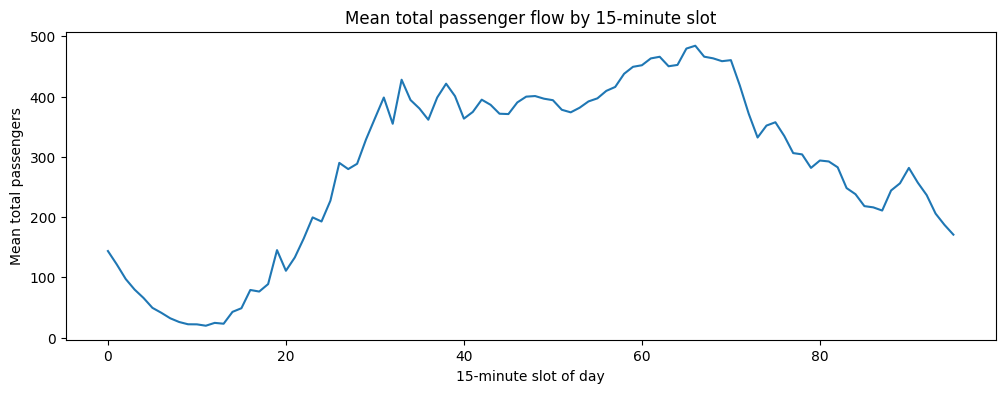

In [11]:
slot_profile = df_15.groupby("slot")["total"].mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(slot_profile.index, slot_profile.values)
ax.set_title("Mean total passenger flow by 15-minute slot")
ax.set_xlabel("15-minute slot of day")
ax.set_ylabel("Mean total passengers")
plt.show()

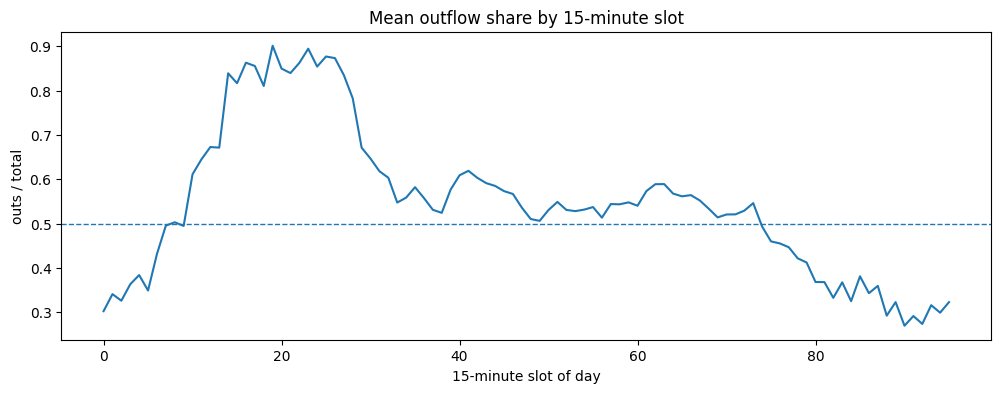

In [12]:
slot_direction = df_15.groupby("slot")["outs_share"].mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(slot_direction.index, slot_direction.values)
ax.axhline(0.5, linestyle="--", linewidth=1)
ax.set_title("Mean outflow share by 15-minute slot")
ax.set_xlabel("15-minute slot of day")
ax.set_ylabel("outs / total")
plt.show()

# Saving the modelling dataframe

In [13]:
model_df = df_15[[
    "timestamp",
    "ins",
    "outs",
    "total",
    "outs_share",
    "slot",
    "weekday",
    "month",
    "is_weekend",
]].copy()

model_df.to_parquet("airport_15min_model_data.parquet", index=False)

model_df.head()

,timestamp,ins,outs,total,outs_share,slot,weekday,month,is_weekend
0,2024-04-01 00:00:00+00:00,413.0,84.0,497.0,0.169014,0,0,3,0
1,2024-04-01 00:15:00+00:00,182.0,36.0,218.0,0.165138,1,0,3,0
2,2024-04-01 00:30:00+00:00,104.0,55.0,159.0,0.345912,2,0,3,0
3,2024-04-01 00:45:00+00:00,49.0,34.0,83.0,0.409639,3,0,3,0
4,2024-04-01 01:00:00+00:00,28.0,26.0,54.0,0.481481,4,0,3,0
